# 7. Reading a run

A run writes one results file: the configuration that produced it, each
prediction with its full trajectory, each score row, and the set-level summary.
This notebook reads the most recent full run of Inkling-Small on s98_v2 if it is
present, and the three-episode check otherwise, and shows how to read it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["figure.dpi"] = 110

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")

26521 points over 57.4 days; truth kind transit


In [2]:
import json

candidates = [
    Path("../results/full_v5fit/agent_inkling_small_s98_v2.json"),
    Path("../results/full_v4search/agent_inkling_small_s98_v2.json"),
    Path("../results/smoke/agent_inkling_small_s98_v2_fit3.json"),
]
results_path = next(path for path in candidates if path.exists())
results = json.loads(results_path.read_text())
print(results_path.name, "·", results["system"], "·", len(results["episodes"]), "episodes")
settings = ("backend_base_model", "backend_renderer", "period_rtol", "single_event_credit")
print({key: results["config"][key] for key in settings})

agent_inkling_small_s98_v2.json · tool_agent · 200 episodes
{'backend_base_model': 'thinkingmachines/Inkling-Small', 'backend_renderer': 'tml_v0', 'period_rtol': 0.01, 'single_event_credit': 0.5}


## The summary

The two headline numbers are the false-alarm rate, the share of null episodes with
a detection, and the completeness, the share of injected transits found. The
completeness by transit count shows the regime the single-event form opened.

false-alarm rate 0.027
completeness exact 0.346 with aliases 0.37
mean score 0.583


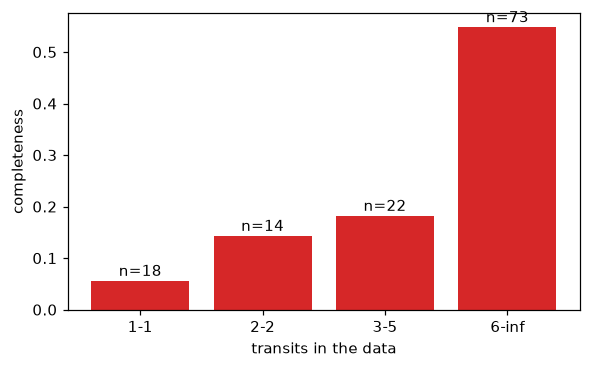

In [3]:
summary = results["summary"]
print("false-alarm rate", round(summary["false_alarm_rate"], 3))
exact, with_aliases = summary["completeness_exact"], summary["completeness_with_aliases"]
print("completeness exact", round(exact, 3), "with aliases", round(with_aliases, 3))
print("mean score", round(summary["mean_score"], 3))
fig, axis = plt.subplots(figsize=(6, 3.5))
labels = list(summary["by_n_transits"])
values = [bin_["completeness"] or 0.0 for bin_ in summary["by_n_transits"].values()]
counts = [bin_["n"] for bin_ in summary["by_n_transits"].values()]
axis.bar(labels, values, color="tab:red")
for index, (value, count) in enumerate(zip(values, counts, strict=True)):
    axis.text(index, value + 0.01, f"n={count}", ha="center")
axis.set_xlabel("transits in the data")
axis.set_ylabel("completeness")
plt.show()

## The outcomes

Each episode has one outcome word. A hit is the right period; an alias is half or
double; a wrong period is a detection at an unrelated period; an event hit is a
credited single event; a miss is an injection the model declined; a true null and a
false alarm are the two answers on an empty star.

In [4]:
from collections import Counter

outcomes = Counter(record["score"]["outcome"] for record in results["episodes"].values())
for outcome, count in outcomes.most_common():
    print(f"{outcome:14s} {count}")

miss           76
true_null      71
hit            43
wrong_period   4
event_hit      3
false_alarm    2
alias          1


## One trajectory

The prediction of each episode holds the transcript: each tool call with its
arguments and its result. The cell prints the calls of the first hit, so the reader
sees the procedure the model followed. The `stargazer show` command prints the same
with the tool results summarised.

In [5]:
hits = [episode for episode, record in results["episodes"].items() if record["score"]["outcome"] == "hit"]
first_hit = hits[0]
record = results["episodes"][first_hit]
print(first_hit, "·", record["score"]["outcome"], "· score", record["score"]["score"])
for step, call in enumerate(record["pred"]["transcript"], start=1):
    arguments = {key: value for key, value in call["arguments"].items() if key != "reasoning"}
    print(f"{step:2d} {call['tool']:18s} {arguments}")
print("reasoning:", record["pred"].get("reasoning"))

ep_0001 · hit · score 1.0
 1 summarize          {}
 2 search_signals     {'detrend_window_days': 0.3, 'max_signals': 3, 'min_sde': 10.0}
 3 fold               {'detrend_window_days': 0.3, 'period': 0.7764, 'phase_half_width': 0.5, 't0': 0.1453}
 4 fold               {'detrend_window_days': 0.3, 'period': 0.7764, 'phase_half_width': 0.05, 't0': 0.1453}
 5 fit_transit        {'detrend_window_days': 0.3, 'duration': 0.051, 'period': 0.7764, 't0': 0.1453}
 6 odd_even           {'duration': 0.051, 'period': 0.7764, 't0': 0.1453}
 7 secondary_eclipse  {'detrend_window_days': 0.3, 'duration': 0.051, 'period': 0.7764, 't0': 0.1453}
 8 bls_peaks          {'detrend_window_days': 0.3, 'masks': [{'duration': 0.051, 'period': 0.7764, 't0': 0.1453}], 'max_period': 2.0, 'min_period': 0.5}
 9 submit_prediction  {'depth': 0.0008876, 'detected': True, 'duration': 0.051, 'period': 0.7764, 't0': 0.1453}
reasoning: Strong periodic signal at 0.7764 d with flat-bottom transit, plausible density, consistent o